# Preparation et exploration des données

In [93]:
%matplotlib inline

import logging
from datetime import date,datetime
import pandas as pd
import yaml
import matplotlib.pyplot as plt
import seaborn as sns
import os
import re
import numpy as np
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import langid
from py3langid.langid import LanguageIdentifier, MODEL_FILE
from collections import Counter

import torch
from transformers import BertTokenizer, BertModel
from tqdm import tqdm
import html as html_lib
from wordcloud import WordCloud


In [94]:
FIGURES_DIR = r"C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\reports\figures"
os.makedirs(FIGURES_DIR, exist_ok=True)

def save_fig(name):
    path = os.path.join(FIGURES_DIR, name)
    plt.savefig(path, bbox_inches='tight', dpi=150)
    print(f"Figure sauvegardée : {path}")


In [95]:
nltk.download('stopwords')
nltk.download('punkt_tab')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\veyss\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\veyss\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

### Chargement des données

In [96]:

X_train = pd.read_csv(r"C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\data\raw\X_train_update.csv",sep=",", encoding="utf-8", index_col=0)
y_train = pd.read_csv(r"C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\data\raw\Y_train.csv",sep=",", encoding="utf-8", index_col=0)
# liste des chemins d'accès aux images

data_train = pd.concat([X_train, y_train], axis=1)

images_path = r"C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\data\raw\images\image_train"
image_names = [name for name in os.listdir(images_path)]
print(f"Nombre d'images : {len(image_names)}\nExemple de nom d'image : {image_names[0]}\n")


Nombre d'images : 84916
Exemple de nom d'image : image_1000076039_product_580161.jpg



In [97]:
# Création d'un DataFrame pour les images avec les ids extraits des noms de fichiers
image_list = []
regex = re.compile(r'image_(\d+)_product_(\d+)\.jpg')
for name in image_names:
    match = regex.match(name)
    if match:
        img_id = int(match.group(1))
        product_id = int(match.group(2))
        image_list.append({
            'image_name': name,
            'imageid': int(match.group(1)),
            'productid': int(match.group(2))
        })

image_df = pd.DataFrame(image_list)
print(image_df.head(10))
print(f"\nNombre d'images dans image_df : {len(image_df)} comparé au nombre dans la liste de base {len(image_names)}")

                               image_name     imageid  productid
0     image_1000076039_product_580161.jpg  1000076039     580161
1  image_1000089455_product_348990858.jpg  1000089455  348990858
2  image_1000092894_product_353108104.jpg  1000092894  353108104
3  image_1000093804_product_343306951.jpg  1000093804  343306951
4  image_1000095646_product_344209267.jpg  1000095646  344209267
5  image_1000095647_product_148177050.jpg  1000095647  148177050
6  image_1000099971_product_352683003.jpg  1000099971  352683003
7  image_1000100220_product_352601770.jpg  1000100220  352601770
8  image_1000222973_product_351172420.jpg  1000222973  351172420
9  image_1000228891_product_355017693.jpg  1000228891  355017693

Nombre d'images dans image_df : 84916 comparé au nombre dans la liste de base 84916


In [98]:
data_train = pd.merge(data_train,image_df,on=['productid', 'imageid'],how='left')
data_train["designation"] = data_train["designation"].str.lower()
data_train["description"] = data_train["description"].str.lower()

In [99]:
CLASS_NAMES = {
    10:   "Livres d'occasion",
    40:   "Jeux vidéo",
    50:   "Accessoires gaming",
    60:   "Consoles de jeux",
    1140: "Figurines",
    1160: "Cartes de collection",
    1180: "Figurines / Jeux de rôle",
    1280: "Jouets enfants",
    1281: "Jeux de société",
    1300: "Modélisme",
    1301: "Vêtements / Équipements sport",
    1302: "Jeux d'extérieur",
    1320: "Puériculture",
    1560: "Mobilier",
    1920: "Literie",
    1940: "Alimentation",
    2060: "Décoration / Luminaires",
    2220: "Animalerie",
    2280: "Journaux / Revues",
    2403: "Livres / BD",
    2462: "Jeux PC (dématérialisés)",
    2522: "Fournitures de bureau",
    2582: "Mobilier de jardin",
    2583: "Piscines / Spas",
    2585: "Jardinage",
    2705: "Livres",
    2905: "Jeux / Puzzles",
}

data_train['class_name'] = data_train['prdtypecode'].map(CLASS_NAMES)
print(data_train[['prdtypecode', 'class_name']].drop_duplicates().sort_values('prdtypecode').to_string(index=False))

 prdtypecode                    class_name
          10             Livres d'occasion
          40                    Jeux vidéo
          50            Accessoires gaming
          60              Consoles de jeux
        1140                     Figurines
        1160          Cartes de collection
        1180      Figurines / Jeux de rôle
        1280                Jouets enfants
        1281               Jeux de société
        1300                     Modélisme
        1301 Vêtements / Équipements sport
        1302              Jeux d'extérieur
        1320                  Puériculture
        1560                      Mobilier
        1920                       Literie
        1940                  Alimentation
        2060       Décoration / Luminaires
        2220                    Animalerie
        2280             Journaux / Revues
        2403                   Livres / BD
        2462      Jeux PC (dématérialisés)
        2522         Fournitures de bureau
        258

In [100]:
print(data_train.head())

                                         designation  \
0  olivia: personalisiertes notizbuch / 150 seite...   
1  journal des arts (le) n° 133 du 28/09/2001 - l...   
2  grand stylet ergonomique bleu gamepad nintendo...   
3  peluche donald - europe - disneyland 2000 (mar...   
4                               la guerre des tuques   

                                         description   productid     imageid  \
0                                                NaN  3804725264  1263597046   
1                                                NaN   436067568  1008141237   
2  pilot style touch pen de marque speedlink est ...   201115110   938777978   
3                                                NaN    50418756   457047496   
4  luc a des id&eacute;es de grandeur. il veut or...   278535884  1077757786   

   prdtypecode                               image_name          class_name  
0           10  image_1263597046_product_3804725264.jpg   Livres d'occasion  
1         2280   image_100

In [101]:
print('Informations générales:')
print(f'Lignes   : {len(data_train):,}')
print(f'Colonnes : {list(data_train.columns)}')
print(f'Classes  : {data_train["prdtypecode"].nunique()}')
print()
print('Valeurs manquantes:')
missing = data_train.isna().sum()
pct     = data_train.isna().sum()/len(data_train) * 100
pd.DataFrame({'nombre_NaN': missing, 'poucentage_NaN': pct.round(2)})

Informations générales:
Lignes   : 84,916
Colonnes : ['designation', 'description', 'productid', 'imageid', 'prdtypecode', 'image_name', 'class_name']
Classes  : 27

Valeurs manquantes:


,nombre_NaN,poucentage_NaN
designation,0,0.00
description,29800,35.09
productid,0,0.00
imageid,0,0.00
prdtypecode,0,0.00
image_name,0,0.00
class_name,0,0.00


In [102]:
print('Doublons:')
print(f'Lignes dupliquées (productid) : {data_train["productid"].duplicated().sum()}')
print(f'Lignes dupliquées (imageid)   : {data_train["imageid"].duplicated().sum()}')

Doublons:
Lignes dupliquées (productid) : 0
Lignes dupliquées (imageid)   : 0


### Repartition des classes

class_name
Piscines / Spas            10209
Mobilier                    5073
Modélisme                   5045
Décoration / Luminaires     4993
Fournitures de bureau       4989
Name: count, dtype: int64


C:\Users\veyss\AppData\Local\Temp\ipykernel_17940\2569310311.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_counts.index, y=class_counts.values, ax=ax1, palette='Blues_r', legend=False, order=class_counts.index)
C:\Users\veyss\AppData\Local\Temp\ipykernel_17940\2569310311.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(ax1.get_xticklabels(), rotation=45, ha='right')
C:\Users\veyss\AppData\Local\Temp\ipykernel_17940\2569310311.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=pct_class.index, y=pct_class.values, ax=ax2, palette='Blues_r', legend=False,order=class_co

Figure sauvegardée : C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\reports\figures\01_class_distribution.png


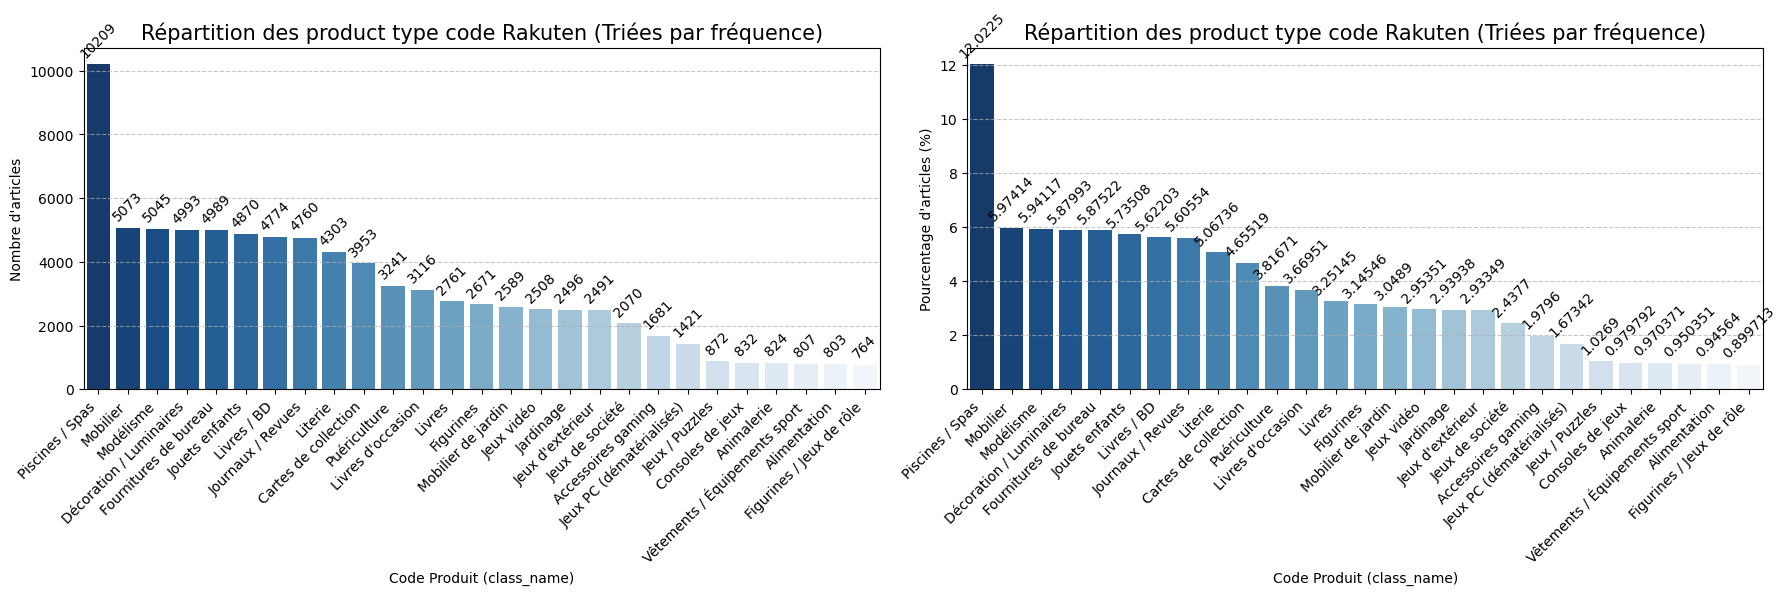

In [103]:
class_counts = data_train['class_name'].value_counts()
pct_class = class_counts / len(data_train) * 100

print(class_counts.head(5))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

sns.barplot(x=class_counts.index, y=class_counts.values, ax=ax1, palette='Blues_r', legend=False, order=class_counts.index)
for container in ax1.containers:
    ax1.bar_label(container, padding=3, fontsize=10, rotation=45)
ax1.set_title('Répartition des product type code Rakuten (Triées par fréquence)', fontsize=15)
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=45, ha='right')
ax1.set_xlabel('Code Produit (class_name)')
ax1.set_ylabel('Nombre d\'articles')
ax1.grid(axis='y', linestyle='--', alpha=0.7)

sns.barplot(x=pct_class.index, y=pct_class.values, ax=ax2, palette='Blues_r', legend=False,order=class_counts.index)
for container in ax2.containers:
    ax2.bar_label(container, padding=3, fontsize=10, rotation=45)
ax2.set_title('Répartition des product type code Rakuten (Triées par fréquence)', fontsize=15)
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=45, ha='right')
ax2.set_xlabel('Code Produit (class_name)')
ax2.set_ylabel('Pourcentage d\'articles (%)')
ax2.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
save_fig("01_class_distribution.png")
plt.show()


#### Analyse — Déséquilibre des classes (Graph 1)

Le dataset présente un **déséquilibre marqué** : la classe *Piscines / Spas* concentre ~12% des produits tandis que *Figurines / Jeux de rôle* n'en représente que ~0,9%.

**Constat métier** : Rakuten est une marketplace généraliste mais dont le catalogue est fortement orienté vers les produits de loisir intérieur (mobilier, décoration, puériculture). Les catégories gaming de niche (consoles, jeux PC dématérialisés) sont sous-représentées, probablement parce que ces produits sont davantage vendus sur des plateformes spécialisées.

**Impact modélisation** : Il faudra recourir à du **class weighting** ou du **sur-échantillonnage** (SMOTE ou augmentation de données) lors de l'entraînement.

**Validation statistique** : test du Chi² d'uniformité sur la distribution des classes.


In [104]:
from scipy.stats import chisquare

observed = class_counts.values
expected = np.full(len(observed), observed.sum() / len(observed))  # distribution uniforme

chi2_stat, p_value = chisquare(f_obs=observed, f_exp=expected)
ratio_max_min = observed.max() / observed.min()

print("Test Chi² — Uniformité de la distribution des classes")
print(f"Chi²     : {chi2_stat:,.1f}")
print(f"p-value  : {p_value:.2e}")
print(f"Ratio max/min : {ratio_max_min:.1f}x")
print()
if p_value < 0.05:
    print("la distribution des classes N'est PAS uniforme (p < 0.05).")
    print(f"  La classe la plus représentée ({class_counts.index[0]}) a {ratio_max_min:.1f}x plus "
          f"de produits que la moins représentée ({class_counts.index[-1]}).")


Test Chi² — Uniformité de la distribution des classes
Chi²     : 36,570.3
p-value  : 0.00e+00
Ratio max/min : 13.4x

la distribution des classes N'est PAS uniforme (p < 0.05).
  La classe la plus représentée (Piscines / Spas) a 13.4x plus de produits que la moins représentée (Figurines / Jeux de rôle).


Top 5 classes les plus fréquentes:
class_name
Piscines / Spas            10209
Mobilier                    5073
Modélisme                   5045
Décoration / Luminaires     4993
Fournitures de bureau       4989

Top 5 classes les moins fréquentes:
class_name
Consoles de jeux                 832
Animalerie                       824
Vêtements / Équipements sport    807
Alimentation                     803
Figurines / Jeux de rôle         764
Figure sauvegardée : C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\reports\figures\01b_class_donut.png


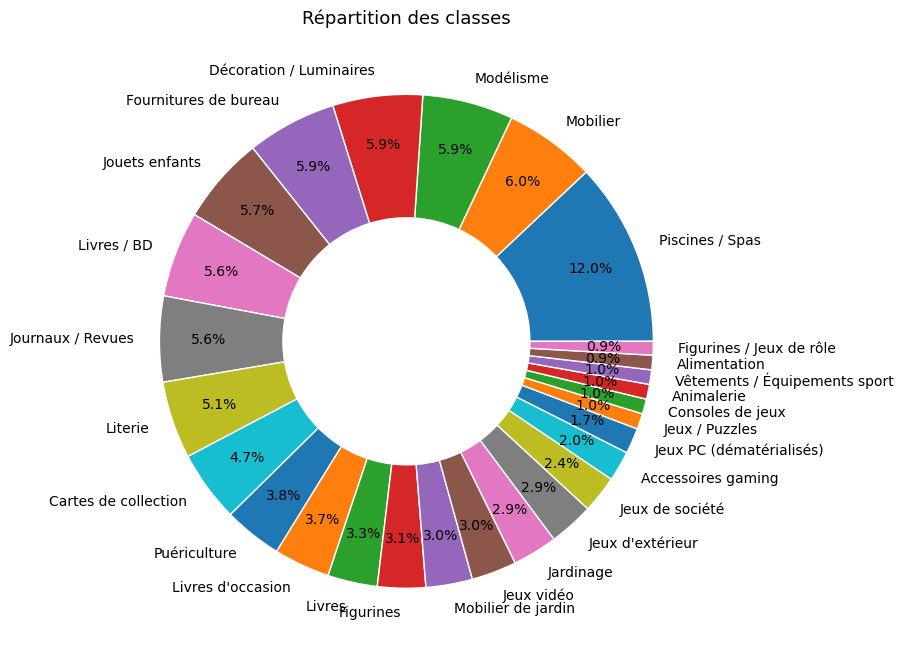

In [105]:
print('Top 5 classes les plus fréquentes:')
print(class_counts.head(5).to_string())
print()
print('Top 5 classes les moins fréquentes:')
print(class_counts.tail(5).to_string())

# Donut chart
fig, ax = plt.subplots(figsize=(9, 9))
wedge_props = dict(width=0.5, edgecolor='white')
ax.pie(class_counts.values, labels=class_counts.index, autopct='%1.1f%%',
       pctdistance=0.8, wedgeprops=wedge_props)
ax.set_title('Répartition des classes', fontsize=13)
plt.tight_layout()
save_fig("01b_class_donut.png")
plt.show()


### Nettoyage des HTML Patterns

In [106]:
html_entity_pattern = re.compile(r'&[a-zA-Z]+;|&#\d+;')
html_tag_pattern    = re.compile(r'<[^>]+>', re.IGNORECASE)

mask_desig = data_train['designation'].str.contains(html_entity_pattern, na=False)
mask_desc  = data_train['description'].str.contains(html_entity_pattern, na=False)
print(f'Avant — entités HTML dans désignation : {mask_desig.sum():,} ({mask_desig.mean()*100:.1f}%)')
print(f'Avant — entités HTML dans description : {mask_desc.sum():,}  ({mask_desc.mean()*100:.1f}%)')
print()
print('Exemples avant nettoyage :')
display(data_train[mask_desc]['description'].dropna().head(5).to_frame())

# Nettoyage : 1) unescape entités  2) suppression balises
def clean_html(text):
    if not isinstance(text, str):
        return text
    text = html_lib.unescape(text)            # &amp; → &,  &eacute; → é
    text = html_lib.unescape(text)            # double passe pour les entités imbriquées
    text = html_tag_pattern.sub(' ', text)    # <br />, </li>, <BR /> → espace
    text = re.sub(r'\s+', ' ', text).strip() # espaces multiples → un seul
    return text

data_train['designation'] = data_train['designation'].apply(clean_html)
data_train['description'] = data_train['description'].apply(clean_html)

still_d = data_train['designation'].str.contains(html_entity_pattern, na=False).sum()
still_s = data_train['description'].str.contains(html_entity_pattern, na=False).sum()
tag_d   = data_train['designation'].str.contains(html_tag_pattern, na=False).sum()
tag_s   = data_train['description'].str.contains(html_tag_pattern, na=False).sum()
print(f'\nAprès — entités restantes  — désignation : {still_d}  |  description : {still_s}')
print(f'Après — balises restantes  — désignation : {tag_d}    |  description : {tag_s}')

display(data_train[mask_desc]['description'].dropna().head(5).to_frame())


Avant — entités HTML dans désignation : 989 (1.2%)
Avant — entités HTML dans description : 35,030  (41.3%)

Exemples avant nettoyage :


,description
4,luc a des id&eacute;es de grandeur. il veut or...
9,tente pliante v3s5 pro pvc 500 gr/m² - 3 x 4m5...
11,canapé et fauteuil chesterfield en cuir antiqu...
13,paire de voilages droits fantaisie qui mettra ...
14,matelas:<br />â· accueil : ferme .<br />â· sou...



Après — entités restantes  — désignation : 0  |  description : 0
Après — balises restantes  — désignation : 0    |  description : 0


,description
4,luc a des idées de grandeur. il veut organiser...
9,tente pliante v3s5 pro pvc 500 gr/m² - 3 x 4m5...
11,canapé et fauteuil chesterfield en cuir antiqu...
13,paire de voilages droits fantaisie qui mettra ...
14,matelas: â· accueil : ferme . â· soutien : trè...


### Detection langue


In [107]:
identifier = LanguageIdentifier.from_pickled_model(MODEL_FILE,norm_probs=True)  #https://github.com/adbar/py3langid
identifier.set_languages(['fr', 'en', 'es', 'de'])

def detect_lang(text, identifier):
    if pd.isna(text) or len(str(text)) < 5:
        return 'unknown'
    
    lang, prob = identifier.classify(str(text))
    if prob < 0.8: # est ce que c'est trop ?
        return 'unknown'
    return lang

text = data_train['designation'] + ' ' + data_train['description'].fillna('')
data_train['language'] = text.apply(lambda x: detect_lang(x, identifier))

Figure sauvegardée : C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\reports\figures\02_language_distribution.png


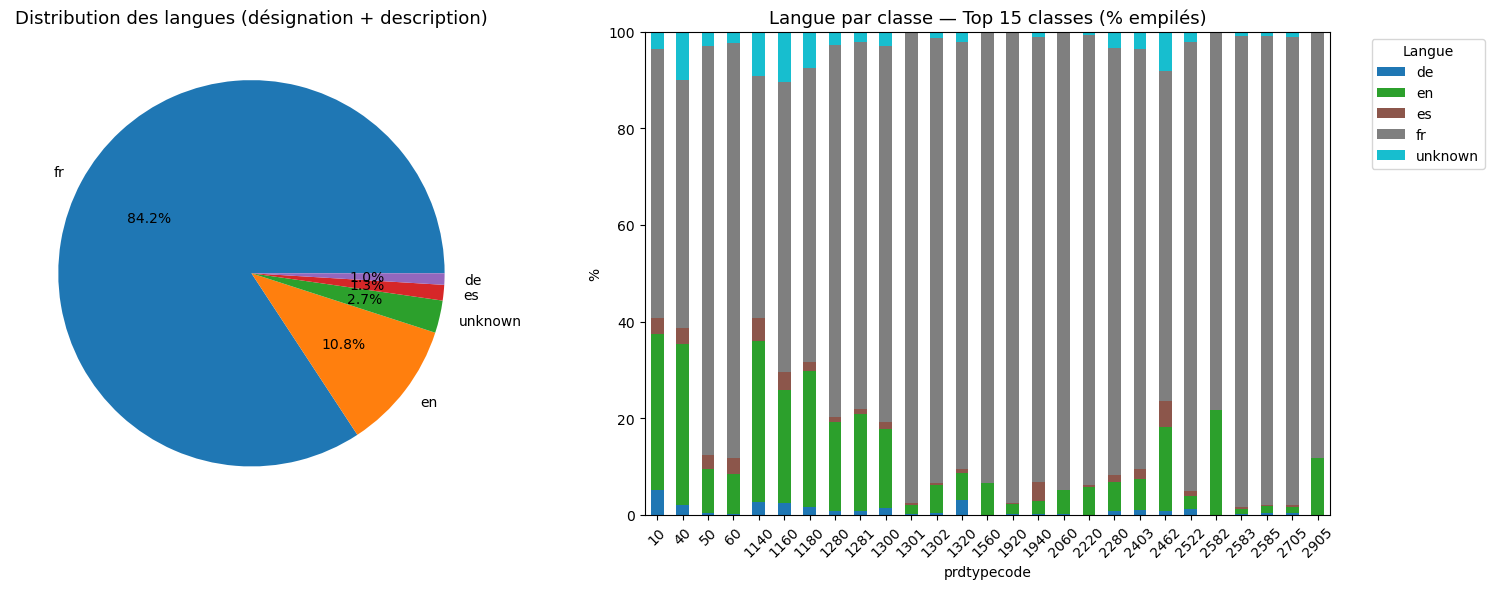

In [108]:
fig, (ax1,ax2)  = plt.subplots(1, 2, figsize=(16, 6))

lang_counts = data_train['language'].value_counts()
ax1.pie(lang_counts.values, labels=lang_counts.index, autopct='%1.1f%%')
ax1.set_title('Distribution des langues (désignation + description)', fontsize=13)

top = data_train['prdtypecode'].value_counts().index
lang_class = (data_train[data_train['prdtypecode'].isin(top)]
              .groupby(['prdtypecode', 'language'])
              .size().unstack(fill_value=0))
lang_class_pct = lang_class.div(lang_class.sum(axis=1), axis=0) * 100
lang_class_pct.plot(kind='bar', stacked=True, ax=ax2, colormap='tab10')
ax2.set_title('Langue par classe — Top 15 classes (% empilés)', fontsize=13)
ax2.set_xlabel('prdtypecode')
ax2.set_ylabel('%')
ax2.tick_params(axis='x', rotation=45)
ax2.legend(title='Langue', bbox_to_anchor=(1.05, 1))

plt.tight_layout()
save_fig("02_language_distribution.png")
plt.show()


#### Analyse — Distribution des langues (Graph 2)

La majorité des produits (~80%) est en **français**, ce qui est cohérent avec la plateforme Rakuten France. Cependant, une proportion non négligeable de produits est en **anglais**, **allemand** ou **espagnol**, et une partie reste classifiée `unknown` (texte trop court ou mixte).

**Constat métier** : Les produits gaming (cartes de collection, jeux PC) sont davantage en anglais car les éditeurs commercialisent souvent des produits avec des titres anglophones en Europe. Les livres et revues sont quasi-exclusivement en français. Cette hétérogénéité linguistique est un **biais du dataset** : un modèle doit être robuste aux langues mixtes plutôt qu'assumer un corpus monolingue.

**Impact modélisation** : l'utilisation d'un tokenizer multilingue (mBERT, XLM-R) sera préférable à un modèle français uniquement (CamemBERT).

**Validation statistique** : test Chi² d'indépendance entre langue et classe.


In [109]:
from scipy.stats import chi2_contingency

contingency = pd.crosstab(data_train['prdtypecode'], data_train['language'])
chi2, p, dof, expected_ct = chi2_contingency(contingency)

print("=== Test Chi² — Indépendance langue × classe ===")
print(f"Chi²    : {chi2:,.1f}")
print(f"p-value : {p:.2e}")
print(f"ddl     : {dof}")
print()
if p < 0.05:
    print("✓ Rejet de H0 : la langue N'est PAS indépendante de la classe (p < 0.05).")
    print("  Certaines classes ont une composition linguistique significativement différente.")
    print()
# Cramér's V pour mesurer la force de l'association
n = contingency.values.sum()
min_dim = min(contingency.shape) - 1
cramers_v = np.sqrt(chi2 / (n * min_dim))
print(f"Cramér's V : {cramers_v:.3f}  (0=aucune association, 1=association parfaite)")


=== Test Chi² — Indépendance langue × classe ===
Chi²    : 15,283.5
p-value : 0.00e+00
ddl     : 104

✓ Rejet de H0 : la langue N'est PAS indépendante de la classe (p < 0.05).
  Certaines classes ont une composition linguistique significativement différente.

Cramér's V : 0.212  (0=aucune association, 1=association parfaite)


In [110]:
print(data_train[data_train['language'] == 'de']['designation'].head(20))

0       olivia: personalisiertes notizbuch / 150 seite...
6              christof e: bildungsprozessen auf der spur
131       dr. mercurius' heilsame reise zum planeten erde
155     scott mitchell - cincinnati bengals - 2001 upp...
382     zöllner schlafsack mit applikation sternchen b...
396         les schtroumpfs - schtroumpf toothbrush 20064
449         army men in space jeu pc big box grosse boite
460                             ich du und die ganze welt
513                  sherwood g: pedigree register vol. 2
571                     collier - zelda - charm windwaker
585           beach toys la reine des neiges - kick board
675     vinyles 33t--coffret 4lp--richard wagner : tan...
683     dahle tableau blanc slim board basic ft 60 x 9...
760                  vw golf variant schabak 1/43-schabak
793                               spa beausoleil 6 places
809     magic mtg - commander 2013 - sek'kuar gardemor...
819     piscine à balles - aire de jeu enfants - avec ...
923     carte 

### Longueur texte

Longueur DÉSIGNATION:
count    84916.0
mean        11.6
std          6.2
min          3.0
25%          7.0
50%         11.0
75%         14.0
max         56.0
Name: len_desig, dtype: float64

Longueur DESCRIPTION (avec-NaN):
count    84916.0
mean        79.5
std        114.5
min          0.0
25%          0.0
50%         35.0
75%        124.0
max       2068.0
Name: len_desc, dtype: float64


C:\Users\veyss\AppData\Local\Temp\ipykernel_17940\377888684.py:33: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1][0].set_xticklabels(axes[1][0].get_xticklabels(), rotation=45, ha='right')
C:\Users\veyss\AppData\Local\Temp\ipykernel_17940\377888684.py:38: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1][1].set_xticklabels(axes[1][1].get_xticklabels(), rotation=45, ha='right')


Figure sauvegardée : C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\reports\figures\03_text_lengths.png


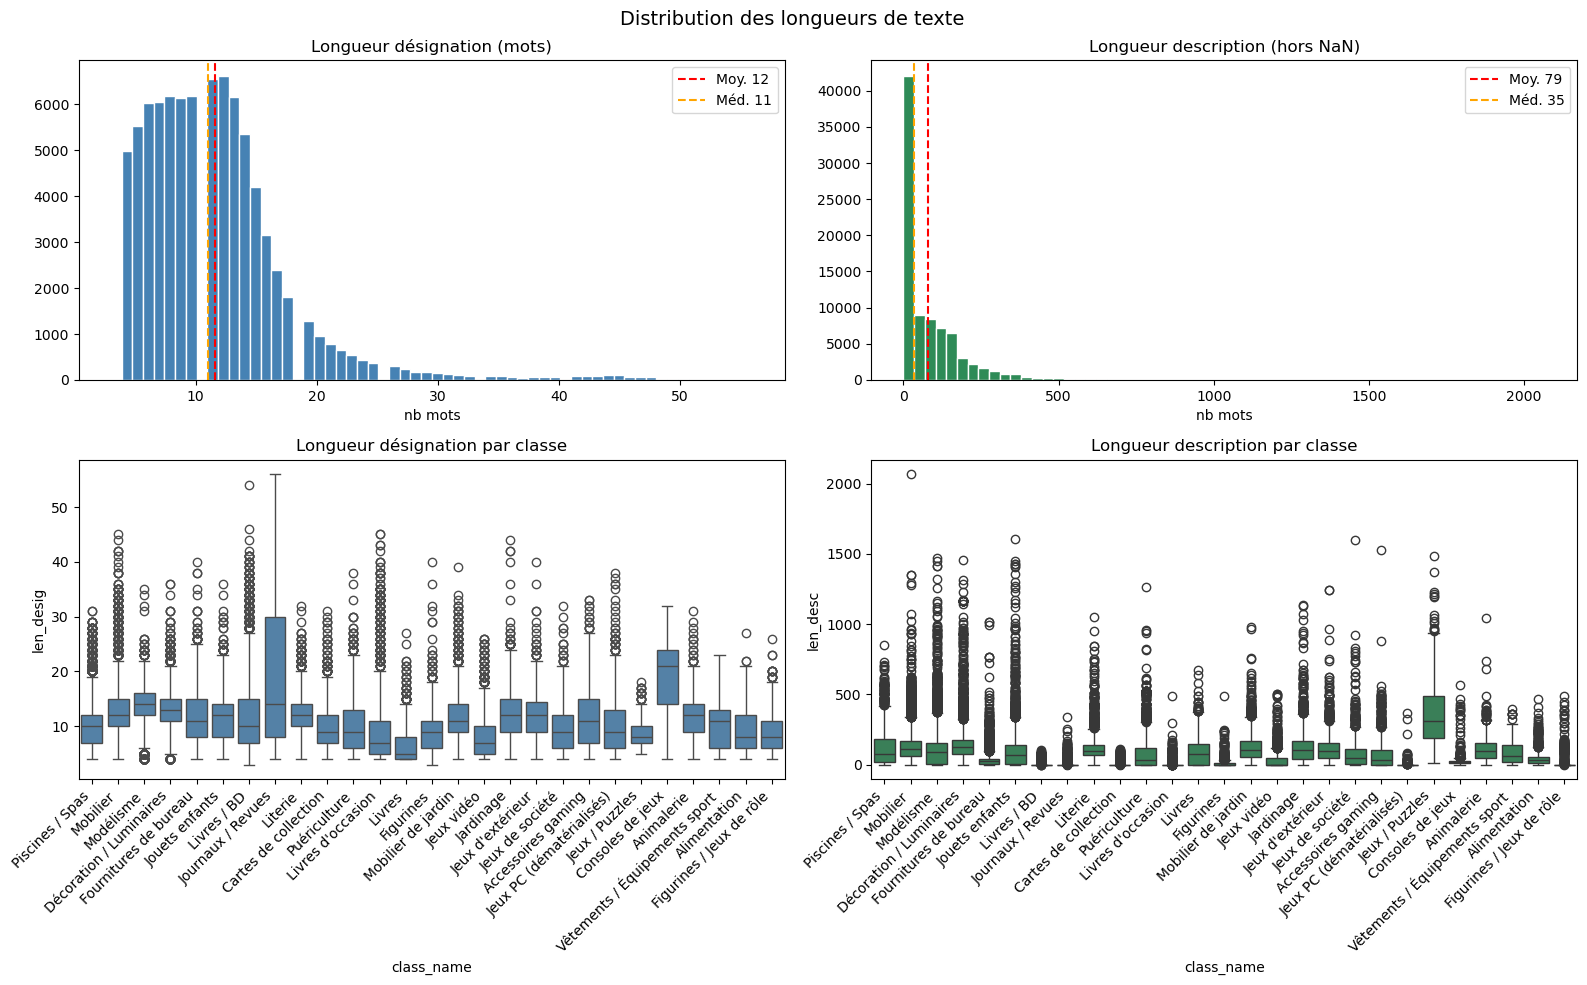

In [111]:
data_train['len_desig'] = data_train['designation'].str.split().str.len().fillna(0).astype(int)
data_train['len_desc']  = data_train['description'].str.split().str.len().fillna(0).astype(int)

print('Longueur DÉSIGNATION:')
print(data_train['len_desig'].describe().round(1))
print()
print('Longueur DESCRIPTION (avec-NaN):')
print(data_train['len_desc'].describe().round(1))

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

axes[0][0].hist(data_train['len_desig'], bins=60, color='steelblue', edgecolor='white')
axes[0][0].axvline(data_train['len_desig'].mean(), color='red', linestyle='--',
               label=f'Moy. {data_train["len_desig"].mean():.0f}')
axes[0][0].axvline(data_train['len_desig'].median(), color='orange', linestyle='--',
               label=f'Méd. {data_train["len_desig"].median():.0f}')
axes[0][0].set_title('Longueur désignation (mots)', fontsize=12)
axes[0][0].set_xlabel('nb mots')
axes[0][0].legend()

axes[0][1].hist(data_train['len_desc'].dropna(), bins=60, color='seagreen', edgecolor='white')
axes[0][1].axvline(data_train['len_desc'].mean(), color='red', linestyle='--',
               label=f'Moy. {data_train["len_desc"].mean():.0f}')
axes[0][1].axvline(data_train['len_desc'].median(), color='orange', linestyle='--',
               label=f'Méd. {data_train["len_desc"].median():.0f}')
axes[0][1].set_title('Longueur description (hors NaN)', fontsize=12)
axes[0][1].set_xlabel('nb mots')
axes[0][1].legend()

sns.boxplot(data=data_train, x='class_name', y='len_desig', order=class_counts.index,
            ax=axes[1][0], color='steelblue')
axes[1][0].set_title('Longueur désignation par classe', fontsize=12)
axes[1][0].set_xticklabels(axes[1][0].get_xticklabels(), rotation=45, ha='right')

sns.boxplot(data=data_train, x='class_name', y='len_desc', order=class_counts.index,
            ax=axes[1][1], color='seagreen')
axes[1][1].set_title('Longueur description par classe', fontsize=12)
axes[1][1].set_xticklabels(axes[1][1].get_xticklabels(), rotation=45, ha='right')

plt.suptitle('Distribution des longueurs de texte', fontsize=14)
plt.tight_layout()
save_fig("03_text_lengths.png")
plt.show()


#### Analyse — Longueur des textes par classe (Graph 3)

Les désignations sont courtes (médiane ~8 mots) et relativement homogènes entre classes. En revanche, les descriptions présentent une **forte variabilité inter-classes** : les classes *Jeux / Puzzles* ou *Mobilier* ont des descriptions très longues (>80 mots en moyenne) tandis que *Livres / BD* ou *Cartes de collection* ont des descriptions quasi-vides (~1 mot).

**Constat métier** : les vendeurs de produits physiques (mobilier, jardinage) rédigent des descriptions détaillées pour convaincre l'acheteur, tandis que les revendeurs de livres et jeux de collection se contentent du titre, car le produit est identifiable par son titre ou son ISBN. Ce comportement de rédaction **différencie les classes de manière discriminante** : la longueur de description peut être une feature utile pour le modèle.

**Validation statistique** : test de Kruskal-Wallis (non-paramétrique) — les distributions de longueur sont-elles identiques entre classes ?


In [112]:
from scipy.stats import kruskal

groups_desig = [g['len_desig'].values for _, g in data_train.groupby('class_name')]
groups_desc  = [g['len_desc'].values  for _, g in data_train.groupby('class_name')]

kw_desig = kruskal(*groups_desig)
kw_desc  = kruskal(*groups_desc)

print("=== Test de Kruskal-Wallis — Longueur par classe ===")
print(f"Désignation : H={kw_desig.statistic:,.1f}, p={kw_desig.pvalue:.2e}")
print(f"Description : H={kw_desc.statistic:,.1f},  p={kw_desc.pvalue:.2e}")
print()
for name, res in [("Désignation", kw_desig), ("Description", kw_desc)]:
    if res.pvalue < 0.05:
        print(f"✓ {name} : les longueurs diffèrent significativement entre classes (p < 0.05).")
        print(f"  → La longueur du texte est une feature discriminante pour la classification.")


=== Test de Kruskal-Wallis — Longueur par classe ===
Désignation : H=13,792.7, p=0.00e+00
Description : H=40,292.5,  p=0.00e+00

✓ Désignation : les longueurs diffèrent significativement entre classes (p < 0.05).
  → La longueur du texte est une feature discriminante pour la classification.
✓ Description : les longueurs diffèrent significativement entre classes (p < 0.05).
  → La longueur du texte est une feature discriminante pour la classification.


### Analyse de la description (valeurs manquantes par classe)

Figure sauvegardée : C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\reports\figures\04_missing_descriptions.png


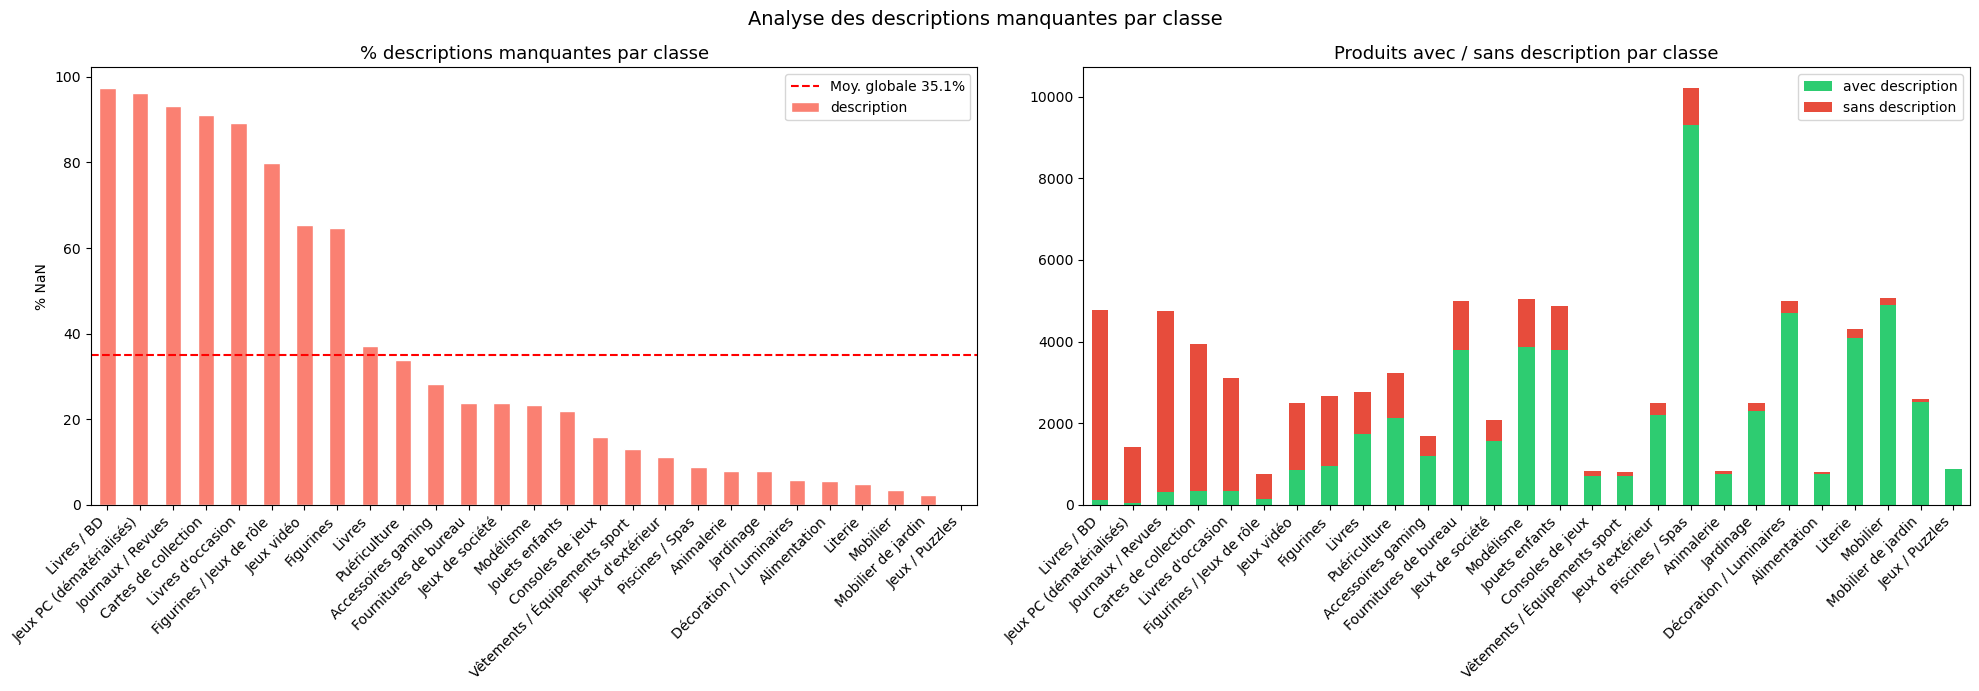


=== Tableau récapitulatif (trié par % manquant) ===
                               nb_produits  avec_desc  sans_desc  pct_manquant
class_name                                                                    
Livres / BD                            126        126       4648          97.4
Jeux PC (dématérialisés)                53         53       1368          96.3
Journaux / Revues                      320        320       4440          93.3
Cartes de collection                   349        349       3604          91.2
Livres d'occasion                      338        338       2778          89.2
Figurines / Jeux de rôle               153        153        611          80.0
Jeux vidéo                             866        866       1642          65.5
Figurines                              945        945       1726          64.6
Livres                                1736       1736       1025          37.1
Puériculture                          2140       2140       1101          34.0

In [113]:
nan_by_class = (data_train.groupby('class_name')['description']
                .apply(lambda x: x.isna().mean() * 100)
                .sort_values(ascending=False))

ordre = nan_by_class.index  

fig, axes = plt.subplots(1, 2, figsize=(20, 7))

nan_by_class.plot(kind='bar', ax=axes[0], color='salmon', edgecolor='white')
axes[0].set_title('% descriptions manquantes par classe', fontsize=13)
axes[0].set_xlabel('')
axes[0].set_ylabel('% NaN')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')
axes[0].axhline(data_train['description'].isna().mean()*100, color='red',
                linestyle='--',
                label=f'Moy. globale {data_train["description"].isna().mean()*100:.1f}%')
axes[0].legend()

has_desc = (data_train.groupby('class_name')['description']
            .apply(lambda x: pd.Series({'avec': x.notna().sum(), 'sans': x.isna().sum()}))
            .unstack()
            .reindex(ordre))  

has_desc.plot(kind='bar', stacked=True, ax=axes[1], color=['#2ecc71', '#e74c3c'])
axes[1].set_title('Produits avec / sans description par classe', fontsize=13)
axes[1].set_xlabel('')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')
axes[1].legend(['avec description', 'sans description'])

plt.suptitle('Analyse des descriptions manquantes par classe', fontsize=14)
plt.tight_layout()
save_fig("04_missing_descriptions.png")
plt.show()

recap = data_train.groupby('class_name').agg(
    nb_produits  = ('description', 'count'),
    avec_desc    = ('description', lambda x: x.notna().sum()),
    sans_desc    = ('description', lambda x: x.isna().sum()),
    pct_manquant = ('description', lambda x: round(x.isna().mean() * 100, 1)),
).reindex(ordre)

print('\n=== Tableau récapitulatif (trié par % manquant) ===')
print(recap.to_string())


#### Analyse — Descriptions manquantes par classe (Graph 4)

35% des produits n'ont **aucune description**. Ce taux varie fortement selon les classes : certaines (livres, journaux, cartes de collection, jeux PC dématérialisés) ont une très forte proportion de descriptions vides, tandis que d'autres (mobilier, literie, jardinage) sont quasi-exhaustives.

**Constat métier** : les descriptions manquantes ne sont pas **Missing At Random (MAR)** — elles sont structurellement liées à la catégorie de produit. Les vendeurs de livres et jeux dématérialisés utilisent le titre comme seul identifiant (le produit est standardisé). À l'inverse, les vendeurs de mobilier ou de literie ont besoin de décrire les dimensions, matériaux et caractéristiques techniques pour rassurer l'acheteur.

**Impact modélisation** : imputer les descriptions manquantes par une chaîne vide (ou par la désignation) est suffisant ici, car la désignation seule contient déjà l'information discriminante pour ces classes. Ne pas supprimer ces lignes — elles représentent 35% du dataset.

**Validation statistique** : test Chi² — le caractère manquant de la description est-il indépendant de la classe ?


In [114]:
data_train['has_desc'] = data_train['description'].notna().astype(int)
contingency_desc = pd.crosstab(data_train['class_name'], data_train['has_desc'])

chi2_desc, p_desc, dof_desc, _ = chi2_contingency(contingency_desc)
print("=== Test Chi² — Indépendance description manquante × classe ===")
print(f"Chi²    : {chi2_desc:,.1f}")
print(f"p-value : {p_desc:.2e}")
print(f"ddl     : {dof_desc}")
print()
if p_desc < 0.05:
    print("la présence de description N'est PAS indépendante de la classe (p < 0.05).")
    print("  → Les descriptions manquantes sont un phénomène structurel lié au type de produit (MCAR rejeté).")
    print()
print("Taux de description manquante par classe (top 5 / bas 5) :")
nan_pct = data_train.groupby('class_name')['description'].apply(lambda x: x.isna().mean()*100).sort_values(ascending=False)
print(nan_pct.head(5).round(1).to_string())
print("...")
print(nan_pct.tail(5).round(1).to_string())


=== Test Chi² — Indépendance description manquante × classe ===
Chi²    : 43,757.8
p-value : 0.00e+00
ddl     : 26

la présence de description N'est PAS indépendante de la classe (p < 0.05).
  → Les descriptions manquantes sont un phénomène structurel lié au type de produit (MCAR rejeté).

Taux de description manquante par classe (top 5 / bas 5) :
class_name
Livres / BD                 97.4
Jeux PC (dématérialisés)    96.3
Journaux / Revues           93.3
Cartes de collection        91.2
Livres d'occasion           89.2
...
class_name
Alimentation          5.6
Literie               4.8
Mobilier              3.5
Mobilier de jardin    2.4
Jeux / Puzzles        0.0


### Frequence des mots et stop words

In [115]:
stop_fr = set(stopwords.words('french'))
stop_en = set(stopwords.words('english'))
stop_de = set(stopwords.words('german'))
stop_es = set(stopwords.words('spanish'))
all_stopwords = stop_fr | stop_en | stop_de | stop_es
# Ponctuation et symboles
all_stopwords.update([
    ',', '.', '``', '@', '*', '(', ')', '...', '!', '?',
    '-', '_', '>', '<', ':', '/', '=', '--', '©', '~',
    ';', '\\', 'x', '+', "''", "'", '"', '«', '»',
    '|', '&', '%', '$', '#', '°', '^', '`','n','n°'
])

# Noms de balises HTML (après tokenisation, <br /> → '<', 'br', '/', '>')
all_stopwords.update([
    'br', 'p', 'div', 'span', 'li', 'ul', 'ol', 'tr', 'td', 'th',
    'table', 'strong', 'em', 'b', 'i', 'u', 'a', 'img', 'href',
    'src', 'alt', 'class', 'style', 'font', 'color', 'size',
    'nbsp', 'amp', 'lt', 'gt', 'quot', 'apos',  # entités HTML résiduelles
    'http', 'https', 'www',                       # URLs
])

print(f'Total stopwords : {len(all_stopwords)}')

Total stopwords : 932


In [116]:
def top_words(series, n=20, title=''):
    tokens = [w for text in series.dropna() for w in str(text).split()
              if w not in all_stopwords and len(w) > 2]
    mc = Counter(tokens).most_common(n)
    mots, freq = zip(*mc)
    fig, ax = plt.subplots(figsize=(14, 5))
    sns.barplot(x=list(mots), y=list(freq), ax=ax, palette='viridis')
    ax.set_title(title or f'Top {n} mots', fontsize=13)
    ax.set_ylabel('Fréquence')
    ax.tick_params(axis='x', rotation=45)
    plt.tight_layout()
    plt.show()
    return Counter(tokens)

In [117]:
# Nettoyage : tokenisation + suppression stopwords
def clean_tokens(text):
    if pd.isna(text):
        return ''
    tokens = word_tokenize(str(text).lower())
    return ' '.join(t for t in tokens if t not in all_stopwords and len(t) > 1)

data_train['designation_clean'] = data_train['designation'].apply(clean_tokens)
print('Désignation nettoyée :')
data_train[['designation', 'designation_clean']].head(5)

Désignation nettoyée :


,designation,designation_clean
0,olivia: personalisiertes notizbuch / 150 seite...,olivia personalisiertes notizbuch 150 seiten p...
1,journal des arts (le) n° 133 du 28/09/2001 - l...,journal arts 133 28/09/2001 l'art marche salon...
2,grand stylet ergonomique bleu gamepad nintendo...,grand stylet ergonomique bleu gamepad nintendo...
3,peluche donald - europe - disneyland 2000 (mar...,peluche donald europe disneyland 2000 marionne...
4,la guerre des tuques,guerre tuques


In [118]:
data_train['description_clean'] = data_train['description'].apply(clean_tokens)
print('Description nettoyée :')
data_train[['description', 'description_clean']].head(5)

Description nettoyée :


,description,description_clean
0,NaN,
1,NaN,
2,pilot style touch pen de marque speedlink est ...,pilot touch pen marque speedlink stylet ergono...
3,NaN,
4,luc a des idées de grandeur. il veut organiser...,luc idées grandeur veut organiser jeu guerre b...


In [ ]:
text_desig = ' '.join(data_train['designation_clean'].dropna())
text_desc  = ' '.join(data_train['description_clean'].dropna())

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

wc_desig = WordCloud(width=900, height=600, background_color='white', max_words=200).generate(text_desig)
axes[0].imshow(wc_desig, interpolation='bilinear')
axes[0].axis('off')
axes[0].set_title('Nuage de mots — désignation', fontsize=13)

wc_desc = WordCloud(width=900, height=600, background_color='white', max_words=200).generate(text_desc)
axes[1].imshow(wc_desc, interpolation='bilinear')
axes[1].axis('off')
axes[1].set_title('Nuage de mots — description', fontsize=13)

plt.tight_layout()
save_fig("05_wordclouds.png")
plt.show()


#### Analyse — Nuages de mots & Top mots par classe (Graph 5)

Le vocabulaire des désignations est dominé par des termes génériques de la marketplace (noms de marques, couleurs, tailles). Le vocabulaire des descriptions est plus riche et technique (matériaux, dimensions, caractéristiques).

**Constat métier** : après suppression des stopwords, les mots restants sont majoritairement des **noms de produits, marques ou termes techniques** propres à chaque catégorie. Le nuage de description confirme que certains vendeurs utilisent beaucoup de texte marketing ("qualité", "livraison", "garantie"). Ces termes sont peu discriminants pour la classification et pourraient être ajoutés à la liste de stopwords lors du preprocessing.

**Constat sur le top 3 des classes** : chaque classe possède un vocabulaire caractéristique bien distinct, ce qui est une bonne nouvelle — le signal textuel est fort pour la classification. Les mots les plus fréquents d'une classe sont rarement les plus fréquents d'une autre.

**Validation statistique** : calcul du taux de chevauchement du vocabulaire top-20 entre les 3 premières classes.


In [ ]:
top3_classes = data_train['class_name'].value_counts().head(3).index.tolist()
top_vocab = {}
for cls in top3_classes:
    tokens = [w for text in data_train[data_train['class_name'] == cls]['designation_clean']
              for w in text.split() if len(w) > 2]
    top_vocab[cls] = set(w for w, _ in Counter(tokens).most_common(20))

print("=== Chevauchement du vocabulaire Top-20 entre les 3 premières classes ===")
for i, c1 in enumerate(top3_classes):
    for c2 in top3_classes[i+1:]:
        overlap = top_vocab[c1] & top_vocab[c2]
        pct = len(overlap) / 20 * 100
        print(f"  {c1[:20]:20s} ∩ {c2[:20]:20s} : {len(overlap)}/20 mots communs ({pct:.0f}%)")
        if overlap:
            print(f"    Mots communs : {', '.join(sorted(overlap))}")
print()
print("→ Un faible chevauchement confirme que chaque classe a un vocabulaire distinct.")


In [ ]:
# Mots les plus fréquents pour les 3 premières classes
top3_classes = data_train['class_name'].value_counts().head(3).index.tolist()
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

for ax, cls in zip(axes, top3_classes):
    subset = data_train[data_train['class_name'] == cls]['designation_clean']
    tokens = [w for text in subset for w in text.split() if len(w) > 2]
    mc = Counter(tokens).most_common(12)
    if mc:
        mots, freq = zip(*mc)
        sns.barplot(x=list(freq), y=list(mots), ax=ax, palette='Blues_r')
        ax.set_title(f'Classe {cls} — Top 12 mots', fontsize=11)
        ax.set_xlabel('Fréquence')

plt.suptitle('Mots les plus fréquents par classe (Top 3)', fontsize=13)
plt.tight_layout()
save_fig("05b_top_words_per_class.png")
plt.show()


### Statistiques

In [ ]:
data_train['len_desig'] = data_train['designation_clean'].str.split().str.len().fillna(0).astype(int)
data_train['len_desc']  = data_train['description_clean'].str.split().str.len().fillna(0).astype(int)

In [ ]:
stats = data_train.groupby('class_name').agg(
    nb_produits        = ('designation_clean', 'count'),
    pct_desc_manquante = ('description_clean', lambda x: round(x.isna().mean() * 100, 1)),
    len_desig_moy      = ('len_desig', 'mean'),
    len_desig_med      = ('len_desig', 'median'),
    len_desc_moy       = ('len_desc', lambda x: round(x.dropna().mean(), 1)),
    nb_langues_uniq    = ('language', 'nunique'),
    langue_dominante   = ('language', lambda x: x.value_counts().index[0]),
).round(1)

stats.sort_values('nb_produits', ascending=False)

,nb_produits,pct_desc_manquante,len_desig_moy,len_desig_med,len_desc_moy,nb_langues_uniq,langue_dominante
class_name,,,,,,,
Piscines / Spas,10209,0.0,7.7,7.0,70.0,5,fr
Mobilier,5073,0.0,10.4,10.0,88.3,5,fr
Modélisme,5045,0.0,11.3,12.0,80.0,5,fr
Décoration / Luminaires,4993,0.0,11.0,11.0,101.6,5,fr
Fournitures de bureau,4989,0.0,9.4,9.0,26.6,5,fr
Jouets enfants,4870,0.0,9.8,10.0,64.0,5,fr
Livres / BD,4774,0.0,8.0,6.0,0.6,5,fr
Journaux / Revues,4760,0.0,12.1,9.5,1.5,5,fr
Literie,4303,0.0,10.4,11.0,75.0,5,fr


In [ ]:
pivot = (data_train.groupby(['class_name', 'language'])['len_desig']
         .mean().unstack(fill_value=0).round(0))

plt.figure(figsize=(10, 8))
sns.heatmap(pivot, cmap='YlOrRd', fmt='.0f', linewidths=0.5, annot=True)
plt.title('Longueur moyenne désignation par classe × langue', fontsize=13)
plt.tight_layout()
save_fig("06_heatmap_length_language.png")
plt.show()


#### Analyse — Heatmap longueur × langue (Graph 6)

La heatmap révèle que la longueur des désignations varie selon **l'interaction classe × langue**. Les produits en allemand ont souvent des désignations plus longues (titres composés), tandis que les produits `unknown` ont des désignations très courtes (textes ambigus ou numériques).

**Constat métier** : la longueur de la désignation est un signal combiné de la classe et de la langue. Par exemple, les *Consoles de jeux* en français ont des désignations très longues (listing détaillé des accessoires inclus), tandis que les *Livres* en toutes langues restent courts (titre seul). Cette interaction peut être exploitée via une feature engineéring : `len_desig × langue encodée`.

**Validation statistique** : vérification que la longueur des désignations diffère bien entre langues pour les classes principales.


In [ ]:
# Kruskal-Wallis : longueur désignation diffère-t-elle entre langues ?
lang_groups = [g['len_desig'].values for _, g in data_train.groupby('language') if len(g) > 10]
kw_lang = kruskal(*lang_groups)

print("=== Test Kruskal-Wallis — Longueur désignation par langue ===")
print(f"H = {kw_lang.statistic:.1f}, p = {kw_lang.pvalue:.2e}")
if kw_lang.pvalue < 0.05:
    print("✓ La longueur des désignations diffère significativement entre langues.")
print()
print("Longueur moyenne par langue :")
print(data_train.groupby('language')['len_desig'].agg(['mean', 'median', 'count']).round(1).to_string())


### Texte combiné

In [ ]:
data_train['text_combined'] = (data_train['designation_clean'].fillna('') + ' ' +
                                data_train['description_clean']).str.strip()
data_train['len_combined'] = data_train['text_combined'].str.len()

print(f'Texte combiné — '
      f'min={data_train["len_combined"].min()}  '
      f'moy={data_train["len_combined"].mean():.0f}  '
      f'max={data_train["len_combined"].max()}')

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(data_train['len_combined'], bins=60, color='mediumpurple', edgecolor='white')
ax.axvline(data_train['len_combined'].mean(), color='red', linestyle='--',
           label=f'Moy. {data_train["len_combined"].mean():.0f}')
ax.set_title('Longueur du texte combiné (désignation + description)', fontsize=13)
ax.set_xlabel('Nombre de caractères')
ax.set_ylabel('Fréquence')
ax.legend()
plt.tight_layout()
save_fig("07_combined_text_length.png")
plt.show()

data_train[['prdtypecode', 'text_combined']].head(5)


### Image


In [ ]:
print(f'Images manquantes (join) : {data_train["image_name"].isna().sum()}')
imgs_par_classe = data_train.groupby('prdtypecode')['image_name'].count()
print(f'Images par classe — min: {imgs_par_classe.min()}  '
      f'max: {imgs_par_classe.max()}  '
      f'moy: {imgs_par_classe.mean():.0f}')

Images manquantes (join) : 0
Images par classe — min: 764  max: 10209  moy: 3145


In [ ]:
from PIL import Image

images_path = r"C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\data\raw\images\image_train"

sample = (data_train.groupby('prdtypecode')
          .first().reset_index()[['prdtypecode', 'class_name', 'image_name']].dropna())

# Test sur la première image
row = sample.iloc[0]
img_path = os.path.join(images_path, row['image_name'])
print(f'Chemin testé : {repr(img_path)}')
print(f'Existe       : {os.path.exists(img_path)}')
try:
    img = Image.open(img_path)
    print(f'Image OK     : {img.size} {img.mode}')
except Exception as e:
    print(f'ERREUR       : {type(e).__name__}: {e}')

## Test mbert pour vectorisation

https://huggingface.co/google-bert/bert-base-multilingual-cased

In [ ]:
tokenizer = BertTokenizer.from_pretrained('bert-base-multilingual-cased')
model = BertModel.from_pretrained("bert-base-multilingual-cased")

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

In [ ]:
# CORRECTION : BertModel n'a pas de méthode .encode()
# Pour encoder avec mBERT, utiliser SentenceTransformer ou un pipeline HuggingFace.
# Ici on montre l'encodage correct via mean pooling du dernier état caché.

# NOTE : Cette cellule est coûteuse en temps et mémoire. Elle est fournie à titre d'exemple.
# Pour la modélisation, préférer SentenceTransformer('paraphrase-multilingual-mpnet-base-v2')
# qui encapsule cette logique et est beaucoup plus rapide.

def encode_texts_bert(texts, tokenizer, model, device, batch_size=32, max_length=128):
    """Encode une liste de textes avec mBERT via mean pooling."""
    all_embeddings = []
    model.eval()
    with torch.no_grad():
        for i in tqdm(range(0, len(texts), batch_size), desc="Encoding"):
            batch = texts[i:i+batch_size]
            encoded = tokenizer(
                batch,
                padding=True,
                truncation=True,
                max_length=max_length,
                return_tensors='pt'
            ).to(device)
            outputs = model(**encoded)
            # Mean pooling sur le dernier état caché (hors padding)
            attention_mask = encoded['attention_mask']
            token_embeddings = outputs.last_hidden_state
            input_mask_expanded = attention_mask.unsqueeze(-1).expand(token_embeddings.size()).float()
            embeddings = torch.sum(token_embeddings * input_mask_expanded, 1) / torch.clamp(input_mask_expanded.sum(1), min=1e-9)
            all_embeddings.append(embeddings.cpu().numpy())
    return np.vstack(all_embeddings)

# Exemple sur un sous-ensemble de 100 produits pour valider
sample_texts = data_train['text_combined'].fillna('').head(100).tolist()
# X_bert_sample = encode_texts_bert(sample_texts, tokenizer, model, device, batch_size=16)
# print(f"Shape embeddings : {X_bert_sample.shape}")  # (100, 768)

print("Fonction encode_texts_bert définie.")
print("Décommenter les lignes ci-dessus pour lancer l'encodage sur un échantillon.")
print("Pour l'encodage complet du dataset (~85k produits), utiliser SentenceTransformer")
print("ou exécuter dans un script dédié avec GPU.")


---
## Récapitulatif Preprocessing — Dataset prêt pour la modélisation

### Étapes effectuées
1. **Chargement** : X_train + Y_train + image_df fusionnés → 84 916 produits, 27 classes
2. **Nettoyage HTML** : décodage entités HTML (`&eacute;` → `é`) + suppression balises (`<br />`)
3. **Détection de langue** : classification en fr/en/de/es/unknown (seuil confiance 0.8)
4. **Nettoyage textuel** : tokenisation NLTK, suppression stopwords multilingues + ponctuation
5. **Feature engineering** : `designation_clean`, `description_clean`, `text_combined`, `len_desig`, `len_desc`, `len_combined`, `language`, `has_desc`, `class_name`

### Biais et difficultés identifiés
- **Déséquilibre de classes** (ratio 13:1) → class weighting obligatoire à la modélisation
- **35% de descriptions manquantes** (MNAR — structurel par classe) → imputation par chaîne vide
- **Multilinguisme** (~20% non-français) → tokenizer multilingue requis (mBERT / XLM-R)
- **Variabilité de longueur** élevée entre classes → longueur est une feature discriminante

### Colonnes disponibles pour la modélisation


In [ ]:
print("=== Dataset final — Colonnes disponibles ===")
print(data_train.dtypes.to_string())
print()
print(f"Shape : {data_train.shape}")
print()
print("=== Valeurs manquantes résiduelles ===")
missing_final = data_train.isna().sum()
print(missing_final[missing_final > 0].to_string() if missing_final.sum() > 0 else "Aucune valeur manquante dans les colonnes clés.")
print()

# Colonnes à utiliser pour la modélisation
COLS_TEXT   = ['designation_clean', 'description_clean', 'text_combined']
COLS_FEAT   = ['len_desig', 'len_desc', 'len_combined', 'has_desc']
COLS_META   = ['language', 'image_name']
COL_TARGET  = 'prdtypecode'

print("Colonnes texte     :", COLS_TEXT)
print("Features numériques:", COLS_FEAT)
print("Métadonnées        :", COLS_META)
print("Cible              :", COL_TARGET)
print()
print("Dataset prêt pour la modélisation ✓")

# Export optionnel du dataset preprocessé
# data_train.to_csv(r"C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\data\processed\data_train_preprocessed.csv", index=False)


---
## Preprocessing — Préparation pour la modélisation

Les étapes suivantes transforment le dataset nettoyé en artefacts directement utilisables par des modèles ML et DL.


### Texte brut pour Transformers (text_combined_raw)

On conserve une version **sans suppression de stopwords** pour les modèles BERT/SentenceTransformer qui ont besoin du contexte syntaxique complet.


In [ ]:
# text_combined_raw : designation + description bruts (juste nettoyage HTML déjà fait)
# → à utiliser avec les tokenizers Transformers (mBERT, CamemBERT, SentenceTransformer)
data_train['text_combined_raw'] = (
    data_train['designation'].fillna('') + ' ' +
    data_train['description'].fillna('')
).str.strip()

print(f"text_combined_raw — {len(data_train):,} lignes")
print(f"Exemple (index 2) : {data_train['text_combined_raw'].iloc[2][:120]}")
print()
print("Rappel des deux versions texte disponibles :")
print("  text_combined     → tokenisé NLTK, stopwords supprimés  → TF-IDF / ML classique")
print("  text_combined_raw → texte brut après nettoyage HTML      → Transformers / BERT")


### Encodage de la cible (LabelEncoder)

Les codes `prdtypecode` sont non-consécutifs (10, 40, 50… 2905). Les modèles sklearn et PyTorch attendent des entiers consécutifs de 0 à N-1.


In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
data_train['label'] = le.fit_transform(data_train['prdtypecode'])

label_mapping = dict(zip(le.classes_.tolist(), le.transform(le.classes_).tolist()))
print("Mapping prdtypecode → label (0..26) :")
for code, lbl in sorted(label_mapping.items()):
    cls = CLASS_NAMES.get(code, '?')
    print(f"  {code:4d} → {lbl:2d}  ({cls})")


### Train / Validation split stratifié (80/20)

Le split **stratifié** garantit que chaque classe est représentée proportionnellement dans train et val, ce qui est indispensable avec un déséquilibre de classes 13:1.


In [ ]:
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    data_train,
    test_size=0.2,
    stratify=data_train['label'],
    random_state=42
)

print(f"Train : {len(train_df):,} produits  ({len(train_df)/len(data_train)*100:.0f}%)")
print(f"Val   : {len(val_df):,} produits   ({len(val_df)/len(data_train)*100:.0f}%)")
print()

# Vérification que la stratification est bien respectée
train_dist = train_df['class_name'].value_counts(normalize=True)
val_dist   = val_df['class_name'].value_counts(normalize=True)
check = pd.DataFrame({'train_%': (train_dist*100).round(1), 'val_%': (val_dist*100).round(1)})
check['ecart'] = (check['train_%'] - check['val_%']).abs().round(2)
print("Distribution par classe (écart train/val doit être < 0.2%) :")
print(check.to_string())


### Class weights

Compensent le déséquilibre de classes : les classes rares reçoivent un poids plus élevé dans la loss, forçant le modèle à ne pas les ignorer.


In [ ]:
from sklearn.utils.class_weight import compute_class_weight

classes      = np.sort(data_train['label'].unique())
weights      = compute_class_weight('balanced', classes=classes, y=data_train['label'])
class_weight_dict = dict(zip(classes.tolist(), weights.tolist()))

print("=== Class weights ===")
print(f"min  : {weights.min():.4f}  (classe la plus fréquente)")
print(f"max  : {weights.max():.4f}  (classe la plus rare)")
print(f"ratio: {weights.max()/weights.min():.1f}x")
print()
print("Détail par classe :")
for lbl, w in sorted(class_weight_dict.items()):
    code = le.inverse_transform([lbl])[0]
    cls  = CLASS_NAMES.get(code, '?')
    bar  = '█' * int(w * 5)
    print(f"  label {lbl:2d} ({cls:30s}) : {w:.4f}  {bar}")

print()
print("Usage PyTorch  : criterion = nn.CrossEntropyLoss(weight=torch.tensor(weights, dtype=torch.float).to(device))")
print("Usage sklearn  : LinearSVC(class_weight=class_weight_dict)  ou  LogisticRegression(class_weight='balanced')")


### TF-IDF sur text_combined — Baseline ML

Le TF-IDF (`ngram_range=(1,2)`, `sublinear_tf`) produit une matrice sparse exploitable directement par SVM, Logistic Regression, XGBoost. C'est la **baseline rapide** avant les modèles Deep Learning.


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
import scipy.sparse as sp
import pickle

PROCESSED_DIR = r"C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\data\processed"
MODELS_DIR    = r"C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\models"
os.makedirs(PROCESSED_DIR, exist_ok=True)
os.makedirs(MODELS_DIR,    exist_ok=True)

tfidf = TfidfVectorizer(
    max_features=50_000,
    ngram_range=(1, 2),   # unigrammes + bigrammes
    sublinear_tf=True,    # log(1+tf) → réduit l'impact des mots très fréquents
    min_df=2,             # ignore les termes qui n'apparaissent que 1 fois
)

X_tfidf_train = tfidf.fit_transform(train_df['text_combined'].fillna(''))
X_tfidf_val   = tfidf.transform(val_df['text_combined'].fillna(''))

y_train = train_df['label'].values
y_val   = val_df['label'].values

print(f"Shape TF-IDF train : {X_tfidf_train.shape}")
print(f"Shape TF-IDF val   : {X_tfidf_val.shape}")
sparsity = 1 - X_tfidf_train.nnz / (X_tfidf_train.shape[0] * X_tfidf_train.shape[1])
print(f"Sparsité            : {sparsity:.3%}")
print()

# Sauvegarde
sp.save_npz(os.path.join(PROCESSED_DIR, 'X_tfidf_train.npz'), X_tfidf_train)
sp.save_npz(os.path.join(PROCESSED_DIR, 'X_tfidf_val.npz'),   X_tfidf_val)
np.save(os.path.join(PROCESSED_DIR, 'y_train.npy'), y_train)
np.save(os.path.join(PROCESSED_DIR, 'y_val.npy'),   y_val)
with open(os.path.join(MODELS_DIR, 'tfidf_vectorizer.pkl'), 'wb') as f:
    pickle.dump(tfidf, f)
with open(os.path.join(MODELS_DIR, 'label_encoder.pkl'), 'wb') as f:
    pickle.dump(le, f)

print("Artefacts sauvegardés :")
print(f"  {PROCESSED_DIR}/X_tfidf_train.npz")
print(f"  {PROCESSED_DIR}/X_tfidf_val.npz")
print(f"  {PROCESSED_DIR}/y_train.npy  y_val.npy")
print(f"  {MODELS_DIR}/tfidf_vectorizer.pkl")
print(f"  {MODELS_DIR}/label_encoder.pkl")


### Preprocessing images (resize + normalize)

Les images doivent être redimensionnées à **224×224** (taille standard des CNN ImageNet) et normalisées avec les moyennes/écarts-types d'ImageNet. La fonction `load_and_preprocess_image` sera réutilisée dans le Dataset PyTorch lors de la modélisation.


In [ ]:
from PIL import Image, UnidentifiedImageError
import torchvision.transforms as T

IMAGES_PATH = r"C:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\data\raw\images\image_train"

# Pipeline de transformation standard ImageNet
image_transform = T.Compose([
    T.Resize((224, 224)),                                               # resize forcé 224x224
    T.ToTensor(),                                                       # [0,255] → [0,1]
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) # normes ImageNet
])

def load_and_preprocess_image(image_name, transform=image_transform, images_path=IMAGES_PATH):
    """
    Charge et normalise une image produit Rakuten.
    Retourne un tensor (3, 224, 224). En cas d'erreur, retourne un tenseur noir.
    """
    path = os.path.join(images_path, image_name)
    try:
        img = Image.open(path).convert('RGB')
        return transform(img)
    except (FileNotFoundError, UnidentifiedImageError, OSError):
        return torch.zeros(3, 224, 224)

# Vérification sur 8 images (2 par classe parmi les 4 premières classes)
sample = data_train.groupby('class_name').head(2).head(8)
print("Test preprocessing images :")
print(f"{'image_name':55s}  shape         min     max")
print("-" * 90)
errors = 0
for _, row in sample.iterrows():
    t = load_and_preprocess_image(row['image_name'])
    ok = t.sum().item() != 0
    if not ok:
        errors += 1
    print(f"  {row['image_name'][:52]:52s}  {str(tuple(t.shape)):14s}  {t.min():.3f}  {t.max():.3f}  {'✓' if ok else '✗ ERREUR'}")

print()
print(f"Images chargées OK : {8 - errors}/8")
print()
print("La fonction load_and_preprocess_image() est prête à être utilisée dans un Dataset PyTorch.")


### SentenceTransformer embeddings (Deep Learning)

`paraphrase-multilingual-mpnet-base-v2` supporte nativement fr/en/de/es — parfait pour ce dataset multilingue. Produit des vecteurs de dimension 768, L2-normalisés.

> ⚠️ **Cellule longue** : ~20 min sur CPU, ~2 min sur GPU. Décommenter pour lancer.


In [ ]:
# Installation : pip install sentence-transformers
#
# from sentence_transformers import SentenceTransformer
#
# st_model = SentenceTransformer('paraphrase-multilingual-mpnet-base-v2')
# print(f"Device SentenceTransformer : {st_model.device}")
#
# X_st_train = st_model.encode(
#     train_df['text_combined_raw'].fillna('').tolist(),
#     batch_size=64,
#     show_progress_bar=True,
#     normalize_embeddings=True   # L2-normalize → cosine similarity = dot product
# )
# X_st_val = st_model.encode(
#     val_df['text_combined_raw'].fillna('').tolist(),
#     batch_size=64,
#     show_progress_bar=True,
#     normalize_embeddings=True
# )
#
# print(f"Shape train : {X_st_train.shape}")  # (67932, 768)
# print(f"Shape val   : {X_st_val.shape}")    # (16984, 768)
#
# np.save(os.path.join(PROCESSED_DIR, 'X_st_train.npy'), X_st_train)
# np.save(os.path.join(PROCESSED_DIR, 'X_st_val.npy'),   X_st_val)
# print("Embeddings SentenceTransformer sauvegardés.")

print("SentenceTransformer — cellule prête, décommenter pour lancer l'encodage.")
print("Modèle : paraphrase-multilingual-mpnet-base-v2  (dim=768, multilingue)")
print("Input  : text_combined_raw (texte brut, PAS les stopwords supprimés)")


### Lemmatisation avec spaCy (Bonus)

La lemmatisation réduit les mots à leur forme canonique (*jouets* → *jouet*, *achetées* → *acheter*), ce qui améliore la couverture vocabulaire du TF-IDF. Utile surtout pour les classes avec peu de texte.

> ⚠️ **Cellule longue** : ~15 min sur CPU. Nécessite `pip install spacy` + `python -m spacy download fr_core_news_sm`.


In [ ]:
# pip install spacy
# python -m spacy download fr_core_news_sm
#
# import spacy
# from tqdm import tqdm
# tqdm.pandas()
#
# nlp = spacy.load('fr_core_news_sm', disable=['parser', 'ner'])
#
# def lemmatize(text):
#     if not isinstance(text, str) or len(text.strip()) == 0:
#         return ''
#     doc = nlp(text[:10_000])  # limite 10k chars pour éviter les timeouts
#     return ' '.join(
#         t.lemma_.lower() for t in doc
#         if not t.is_stop and not t.is_punct and len(t.text) > 1
#     )
#
# print("Lemmatisation désignation...")
# data_train['designation_lemma']    = data_train['designation'].fillna('').progress_apply(lemmatize)
# print("Lemmatisation texte combiné...")
# data_train['text_combined_lemma']  = data_train['text_combined_raw'].fillna('').progress_apply(lemmatize)
#
# print("\nExemple avant/après lemmatisation :")
# idx = data_train['designation'].str.len().idxmax()
# print(f"  Avant : {data_train.loc[idx, 'designation'][:100]}")
# print(f"  Après : {data_train.loc[idx, 'designation_lemma'][:100]}")
# print("\nLemmatisation terminée.")

print("Lemmatisation spaCy — décommenter pour activer.")
print("Prérequis : pip install spacy && python -m spacy download fr_core_news_sm")


### Normalisation des features numériques

`len_desig`, `len_desc`, `len_combined` sont sur des échelles très différentes (0–500 mots). Le StandardScaler les centre et réduit, ce qui est requis par SVM et Logistic Regression.


In [ ]:
from sklearn.preprocessing import StandardScaler

NUMERIC_COLS = ['len_desig', 'len_desc', 'len_combined']

scaler   = StandardScaler()
train_df = train_df.copy()
val_df   = val_df.copy()

train_df[NUMERIC_COLS] = scaler.fit_transform(train_df[NUMERIC_COLS])
val_df[NUMERIC_COLS]   = scaler.transform(val_df[NUMERIC_COLS])   # fit sur train uniquement

print("Features numériques après StandardScaler (train) :")
print(train_df[NUMERIC_COLS].describe().round(3))
print()
print("Features numériques après StandardScaler (val) :")
print(val_df[NUMERIC_COLS].describe().round(3))

with open(os.path.join(MODELS_DIR, 'numeric_scaler.pkl'), 'wb') as f:
    pickle.dump(scaler, f)
print("\nScaler sauvegardé.")


### Export CSV — Dataset prêt pour la modélisation


In [ ]:
cols_export = [
    'productid', 'imageid', 'image_name',
    'prdtypecode', 'label', 'class_name',
    'language', 'has_desc',
    'text_combined',        # pour TF-IDF / ML classique
    'text_combined_raw',    # pour Transformers
    'len_desig', 'len_desc', 'len_combined'
]

train_path = os.path.join(PROCESSED_DIR, 'train_preprocessed.csv')
val_path   = os.path.join(PROCESSED_DIR, 'val_preprocessed.csv')

train_df[cols_export].to_csv(train_path, index=False, encoding='utf-8')
val_df[cols_export].to_csv(val_path,     index=False, encoding='utf-8')

print(f"Exporté : train_preprocessed.csv  ({len(train_df):,} lignes, {len(cols_export)} colonnes)")
print(f"Exporté : val_preprocessed.csv    ({len(val_df):,} lignes, {len(cols_export)} colonnes)")
print(f"\nRépertoire : {PROCESSED_DIR}")


---
## Bilan Preprocessing

| Artefact | Chemin | Usage |
|----------|--------|-------|
| `train_preprocessed.csv` | `data/processed/` | Dataset train complet |
| `val_preprocessed.csv` | `data/processed/` | Dataset val complet |
| `X_tfidf_train.npz` | `data/processed/` | Matrice sparse TF-IDF train |
| `X_tfidf_val.npz` | `data/processed/` | Matrice sparse TF-IDF val |
| `y_train.npy` / `y_val.npy` | `data/processed/` | Labels encodés (0..26) |
| `tfidf_vectorizer.pkl` | `models/` | Vectorizer TF-IDF fitté |
| `label_encoder.pkl` | `models/` | LabelEncoder (prdtypecode ↔ 0..26) |
| `numeric_scaler.pkl` | `models/` | StandardScaler features numériques |
| `load_and_preprocess_image()` | *défini en mémoire* | Pipeline image pour PyTorch Dataset |
| Embeddings SentenceTransformer | *à générer* | Cellule commentée ci-dessus |

### Résumé des choix

- **Texte ML** : `text_combined` (stopwords supprimés) → TF-IDF 50k features, bigrammes
- **Texte DL** : `text_combined_raw` (brut) → SentenceTransformer / mBERT
- **Images** : resize 224×224, normalisation ImageNet → `load_and_preprocess_image()`
- **Split** : 80/20 stratifié sur `label` (seed=42)
- **Déséquilibre** : `class_weight_dict` calculé → à passer aux modèles
